In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import lognorm, skew
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.metrics import accuracy_score, f1_score

In [8]:
def generate_skewed(n_samples, sigma, seed=42):
    """
    Fixed class separation relative to sigma,
    so difficulty stays comparable across skewness levels.
    """
    rng = np.random.default_rng(seed)
    n_per_class = n_samples // 2
    n_features = 4

    # separation scales with sigma to keep task difficulty stable
    sep = 1.5 * sigma

    X0 = lognorm.rvs(s=sigma, size=(n_per_class, n_features), random_state=seed)
    X1 = lognorm.rvs(s=sigma, size=(n_per_class, n_features), random_state=seed+1)
    X1 += sep  # ALL features shifted, not just feature_0

    X = np.vstack([X0, X1])
    y = np.array([0]*n_per_class + [1]*n_per_class)
    return X, y

In [9]:
def measure_avg_skewness(X, y):
    """Mean absolute skewness across features, averaged over classes."""
    skews = []
    for label in np.unique(y):
        X_class = X[y == label]
        skews.extend([abs(skew(X_class[:, f])) for f in range(X_class.shape[1])])
    return round(np.mean(skews), 4)

In [10]:
def evaluate_with_cv(X, y, n_splits=10, n_repeats=10, k=5):
    """10-fold CV repeated 10 times — same as paper's methodology."""
    knn_accs, nc_accs = [], []

    for repeat in range(n_repeats):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=repeat)
        for train_idx, test_idx in skf.split(X, y):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

            knn = KNeighborsClassifier(n_neighbors=k)
            knn.fit(X_train, y_train)
            knn_accs.append(accuracy_score(y_test, knn.predict(X_test)))

            nc = NearestCentroid()
            nc.fit(X_train, y_train)
            nc_accs.append(accuracy_score(y_test, nc.predict(X_test)))

    return np.mean(knn_accs), np.mean(nc_accs)

 sigma  avg_abs_skewness  knn_acc  nc_acc  gap (NC - KNN)
   0.1            0.2726   0.9174  0.9354          0.0180
   0.3            0.8747   0.9328  0.9261         -0.0067
   0.5            1.5672   0.9473  0.9041         -0.0433
   0.8            2.9147   0.9513  0.8532         -0.0981
   1.2            5.3863   0.9407  0.7335         -0.2072
   1.5            7.5377   0.9247  0.6385         -0.2862
   1.8            9.7300   0.9064  0.5782         -0.3282
   2.1           11.8334   0.8812  0.5411         -0.3401
   2.4           13.7485   0.8656  0.5228         -0.3427
   2.8           15.9076   0.8410  0.5223         -0.3187
   3.0           16.8081   0.8283  0.5214         -0.3069


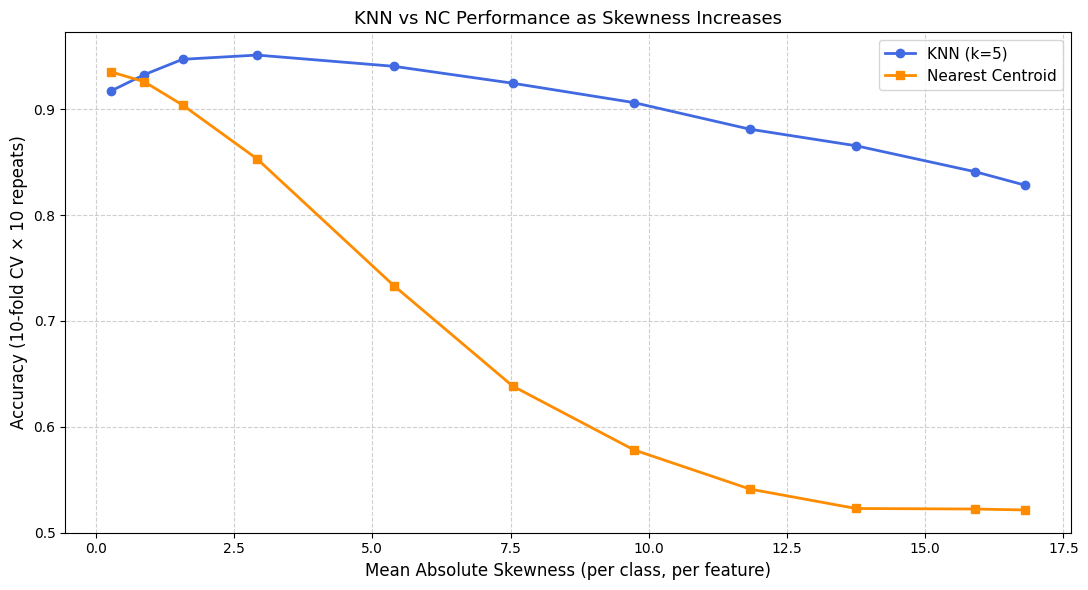

In [11]:
# --- Main experiment ---
sigma_values = [0.1, 0.3, 0.5, 0.8, 1.2, 1.5, 1.8, 2.1, 2.4, 2.8, 3.0]
n_samples = 1200
results = []

for sigma in sigma_values:
    X, y = generate_skewed(n_samples=n_samples, sigma=sigma)
    avg_skew = measure_avg_skewness(X, y)
    knn_acc, nc_acc = evaluate_with_cv(X, y)

    results.append({
        'sigma': sigma,
        'avg_abs_skewness': avg_skew,
        'knn_acc': round(knn_acc, 4),
        'nc_acc': round(nc_acc, 4),
        'gap (NC - KNN)': round(nc_acc - knn_acc, 4)
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

# Plot
fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.plot(df_results['avg_abs_skewness'], df_results['knn_acc'],
         marker='o', linewidth=2, label='KNN (k=5)', color='royalblue')
ax1.plot(df_results['avg_abs_skewness'], df_results['nc_acc'],
         marker='s', linewidth=2, label='Nearest Centroid', color='darkorange')
ax1.set_xlabel('Mean Absolute Skewness (per class, per feature)', fontsize=12)
ax1.set_ylabel('Accuracy (10-fold CV × 10 repeats)', fontsize=12)
ax1.set_title('KNN vs NC Performance as Skewness Increases', fontsize=13)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

=== KURTOSIS EXPERIMENT ===
 df  avg_abs_kurtosis  knn_acc  nc_acc  gap (NC - KNN)
100            0.1403   0.9975  0.9975          0.0000
 50            0.1307   0.9969  0.9975          0.0006
 30            0.2166   0.9983  0.9975         -0.0008
 20            0.3310   0.9967  0.9975          0.0008
 15            0.4990   0.9961  0.9958         -0.0003
 12            0.6505   0.9982  0.9992          0.0010
 10            0.9841   0.9948  0.9958          0.0011
  8            1.3420   0.9944  0.9958          0.0014
  7            1.7240   0.9938  0.9950          0.0012
  6            2.6544   0.9939  0.9926         -0.0013
  5            4.0558   0.9934  0.9917         -0.0017


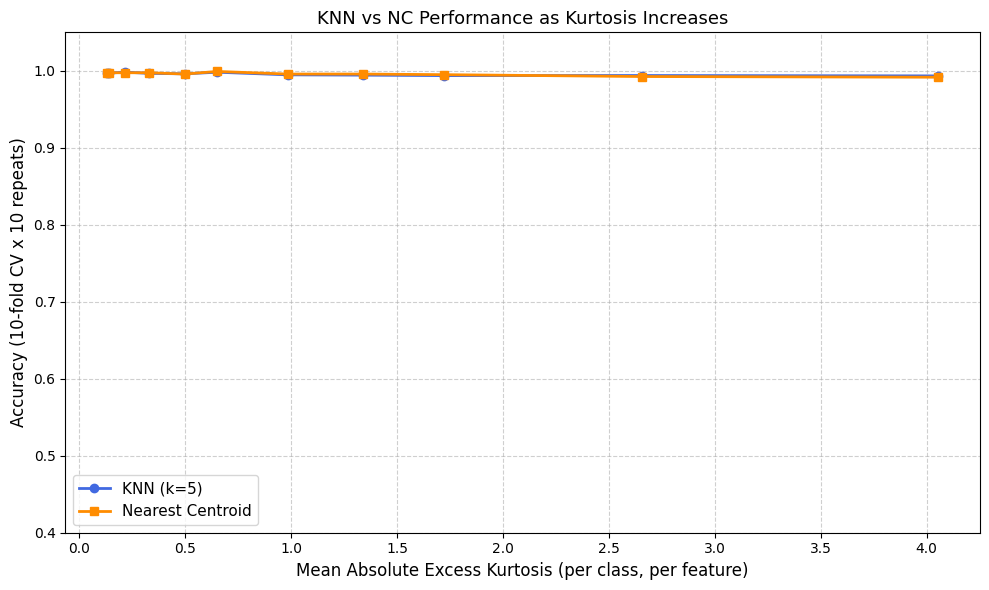


=== SEPARABILITY EXPERIMENT ===
 centre_distance  knn_acc  nc_acc  gap (NC - KNN)
             0.3   0.5289  0.5598          0.0308
             0.5   0.5382  0.6017          0.0635
             0.8   0.5917  0.6648          0.0731
             1.0   0.6354  0.7028          0.0673
             1.3   0.6896  0.7597          0.0701
             1.6   0.7474  0.8057          0.0583
             2.0   0.8218  0.8584          0.0366
             2.5   0.8848  0.9024          0.0177
             3.0   0.9291  0.9345          0.0054
             4.0   0.9719  0.9797          0.0078


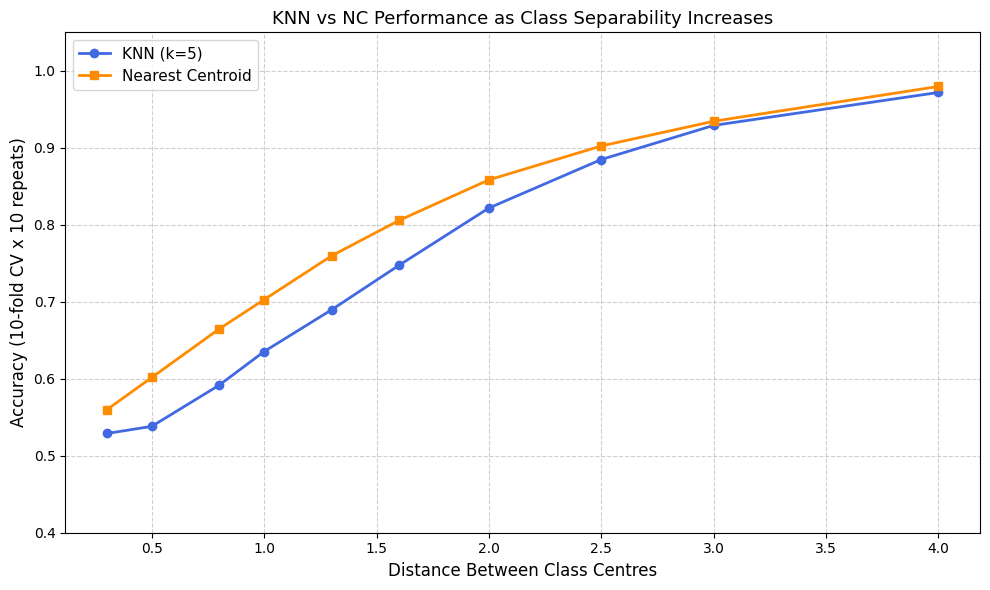


=== COMPACTNESS EXPERIMENT ===
 cluster_std  knn_acc  nc_acc  gap (NC - KNN)
         0.3   1.0000  1.0000          0.0000
         0.5   1.0000  1.0000          0.0000
         0.8   0.9922  0.9928          0.0006
         1.0   0.9719  0.9797          0.0078
         1.3   0.9354  0.9399          0.0045
         1.6   0.8848  0.9024          0.0177
         2.0   0.8218  0.8584          0.0366
         2.5   0.7474  0.8057          0.0583
         3.0   0.6956  0.7642          0.0687
         3.5   0.6609  0.7300          0.0691
         4.0   0.6354  0.7028          0.0673


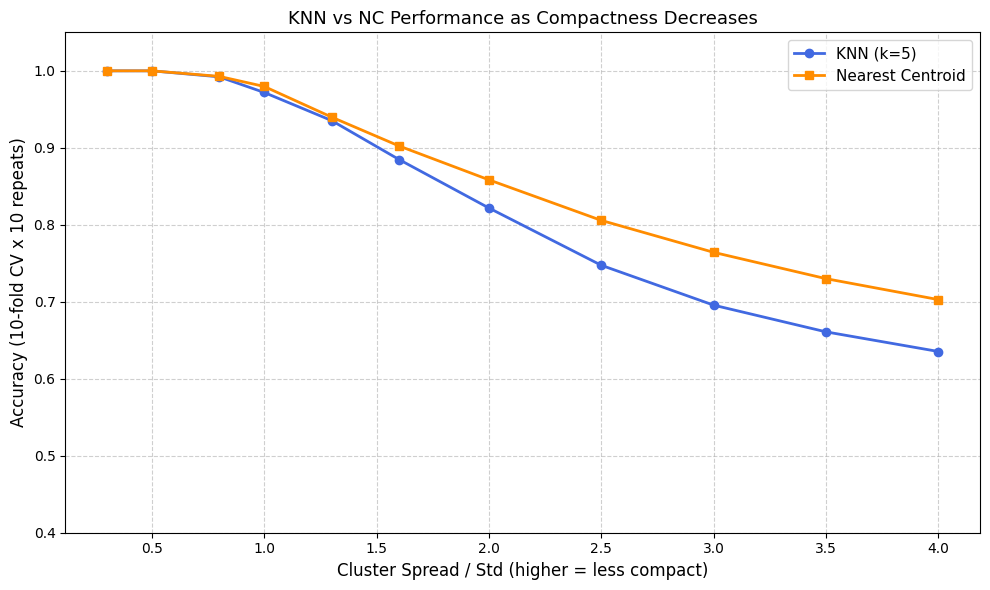


=== MODALITY EXPERIMENT ===
 n_modes  knn_acc  nc_acc  gap (NC - KNN)
       1   0.9631  0.9721          0.0090
       2   0.9657  0.9729          0.0073
       3   0.9638  0.9727          0.0088
       4   0.9625  0.9725          0.0100
       5   0.9662  0.9728          0.0067
       6   0.9673  0.9728          0.0055
       8   0.9656  0.9727          0.0071
      10   0.9695  0.9727          0.0032
      12   0.9652  0.9727          0.0076


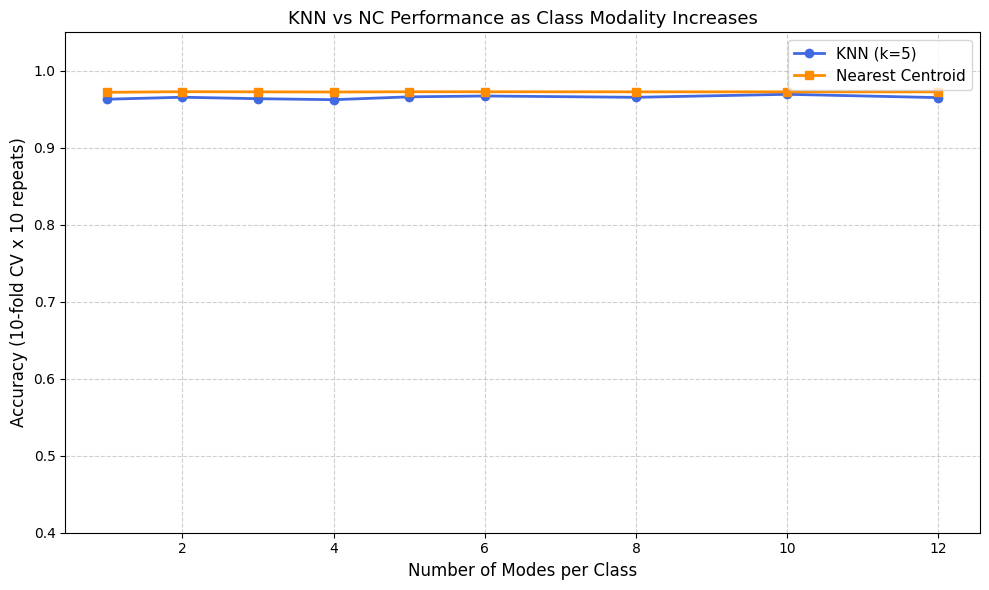

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as t_dist, kurtosis
from sklearn.datasets import make_blobs
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.metrics import accuracy_score

# ─── Shared CV evaluator ──────────────────────────────────────────────────────

def evaluate_with_cv(X, y, n_splits=10, n_repeats=10, k=5):
    knn_accs, nc_accs = [], []
    for repeat in range(n_repeats):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=repeat)
        for train_idx, test_idx in skf.split(X, y):
            X_tr, X_te = X[train_idx], X[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_te = scaler.transform(X_te)
            knn = KNeighborsClassifier(n_neighbors=k)
            knn.fit(X_tr, y_tr)
            knn_accs.append(accuracy_score(y_te, knn.predict(X_te)))
            nc = NearestCentroid()
            nc.fit(X_tr, y_tr)
            nc_accs.append(accuracy_score(y_te, nc.predict(X_te)))
    return np.mean(knn_accs), np.mean(nc_accs)

def plot_results(df, x_col, x_label, title):
    plt.figure(figsize=(10, 6))
    plt.plot(df[x_col], df['knn_acc'], marker='o', linewidth=2,
             label='KNN (k=5)', color='royalblue')
    plt.plot(df[x_col], df['nc_acc'], marker='s', linewidth=2,
             label='Nearest Centroid', color='darkorange')
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Accuracy (10-fold CV x 10 repeats)', fontsize=12)
    plt.title(title, fontsize=13)
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim(0.4, 1.05)
    plt.tight_layout()
    plt.show()

# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 2 — KURTOSIS
# Problem: t-dist heavy tail adds variance → classes get more separated
# naturally → both classifiers do well. Fix: use fixed std scaling so
# spread stays comparable, and only vary tail heaviness.
# ═════════════════════════════════════════════════════════════════════════════

def generate_heavy_tail(n_samples, df, seed=42):
    """
    Uses Student's t-distribution. Lower df = heavier tail = higher kurtosis.
    Fixed separation=3. StandardScaler later normalises spread,
    so only tail shape drives the difficulty difference.
    """
    sep = 3.0  # fixed — scaler handles spread differences

    X0 = t_dist.rvs(df=df, size=(n_samples // 2, 4), random_state=seed)
    X1 = t_dist.rvs(df=df, size=(n_samples // 2, 4), random_state=seed + 1)
    X1 += sep

    X = np.vstack([X0, X1])
    y = np.array([0] * (n_samples // 2) + [1] * (n_samples // 2))
    return X, y

def measure_avg_kurtosis(X, y):
    vals = []
    for label in np.unique(y):
        X_class = X[y == label]
        vals.extend([abs(kurtosis(X_class[:, f])) for f in range(X_class.shape[1])])
    return round(np.mean(vals), 4)

def run_kurtosis_experiment(n_samples=1200):
    # Start from near-Gaussian (high df) → very heavy tail (low df)
    df_values = [100, 50, 30, 20, 15, 12, 10, 8, 7, 6, 5]
    results = []
    for df in df_values:
        X, y = generate_heavy_tail(n_samples, df)
        avg_kurt = measure_avg_kurtosis(X, y)
        knn_acc, nc_acc = evaluate_with_cv(X, y)
        results.append({
            'df': df,
            'avg_abs_kurtosis': avg_kurt,
            'knn_acc': round(knn_acc, 4),
            'nc_acc':  round(nc_acc,  4),
            'gap (NC - KNN)': round(nc_acc - knn_acc, 4)
        })
    df_res = pd.DataFrame(results)
    print("=== KURTOSIS EXPERIMENT ===")
    print(df_res.to_string(index=False))
    plot_results(df_res, 'avg_abs_kurtosis',
                 'Mean Absolute Excess Kurtosis (per class, per feature)',
                 'KNN vs NC Performance as Kurtosis Increases')
    return df_res


# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 3 — SEPARABILITY
# Gaussian blobs, fixed spread (std=1), increasing centre distance.
# Low distance → hard boundary → NC centroid is closer to correct answer.
# High distance → trivially separable → both perfect.
# Expected: at low separability NC should degrade faster than KNN.
# ═════════════════════════════════════════════════════════════════════════════

def run_separability_experiment(n_samples=1200):
    # Tight range where the decision boundary is actually hard
    distance_values = [0.3, 0.5, 0.8, 1.0, 1.3, 1.6, 2.0, 2.5, 3.0, 4.0]
    results = []
    for dist in distance_values:
        centres = [[0, 0, 0, 0], [dist, 0, 0, 0]]
        X, y = make_blobs(n_samples=n_samples, n_features=4,
                          centers=centres, cluster_std=1.0, random_state=42)
        knn_acc, nc_acc = evaluate_with_cv(X, y)
        results.append({
            'centre_distance': dist,
            'knn_acc': round(knn_acc, 4),
            'nc_acc':  round(nc_acc,  4),
            'gap (NC - KNN)': round(nc_acc - knn_acc, 4)
        })
    df_res = pd.DataFrame(results)
    print("\n=== SEPARABILITY EXPERIMENT ===")
    print(df_res.to_string(index=False))
    plot_results(df_res, 'centre_distance',
                 'Distance Between Class Centres',
                 'KNN vs NC Performance as Class Separability Increases')
    return df_res


# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 4 — COMPACTNESS
# Fixed centres far apart (sep=4), increasing cluster_std.
# Low std → tight compact clusters → both do well.
# High std → diffuse overlapping clusters → tests how each handles spread.
# NC centroid gets pulled toward outliers; KNN uses local votes.
# ═════════════════════════════════════════════════════════════════════════════

def run_compactness_experiment(n_samples=1200):
    std_values = [0.3, 0.5, 0.8, 1.0, 1.3, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0]
    centres = [[0, 0, 0, 0], [4, 0, 0, 0]]  # fixed separation
    results = []
    for std in std_values:
        X, y = make_blobs(n_samples=n_samples, n_features=4,
                          centers=centres, cluster_std=std, random_state=42)
        knn_acc, nc_acc = evaluate_with_cv(X, y)
        results.append({
            'cluster_std': std,
            'knn_acc': round(knn_acc, 4),
            'nc_acc':  round(nc_acc,  4),
            'gap (NC - KNN)': round(nc_acc - knn_acc, 4)
        })
    df_res = pd.DataFrame(results)
    print("\n=== COMPACTNESS EXPERIMENT ===")
    print(df_res.to_string(index=False))
    plot_results(df_res, 'cluster_std',
                 'Cluster Spread / Std (higher = less compact)',
                 'KNN vs NC Performance as Compactness Decreases')
    return df_res


# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 5 — MODALITY
# Each class is n_modes sub-clusters spread across feature space.
# NC computes ONE centroid per class — with many modes this centroid
# lands in empty space between sub-clusters → NC degrades.
# KNN uses local votes → handles multimodality better.
# Fix from before: use a HARD task (small between-class sep, larger spread).
# ═════════════════════════════════════════════════════════════════════════════

def generate_multimodal(n_samples, n_modes, class_sep=3.0, mode_spread=4.0, seed=42):
    """
    class_sep: distance between class 0 and class 1 centre of mass.
    mode_spread: how far sub-clusters are from the class centre — larger
                 means modes are more spread out, making NC centroid less useful.
    """
    rng = np.random.default_rng(seed)
    X_parts, y_parts = [], []

    for cls in range(2):
        n = n_samples // 2
        n_per_mode = n // n_modes
        # Modes spread along feature_1; classes separated along feature_0
        centres = [
            [cls * class_sep, (m - n_modes / 2) * mode_spread, 0, 0]
            for m in range(n_modes)
        ]
        chunks = [rng.normal(loc=c, scale=0.8, size=(n_per_mode, 4))
                  for c in centres]
        X_parts.append(np.vstack(chunks))
        y_parts.append(np.full(n_per_mode * n_modes, cls))

    return np.vstack(X_parts), np.concatenate(y_parts)

def run_modality_experiment(n_samples=1200):
    mode_values = [1, 2, 3, 4, 5, 6, 8, 10, 12]
    results = []
    for n_modes in mode_values:
        X, y = generate_multimodal(n_samples, n_modes)
        knn_acc, nc_acc = evaluate_with_cv(X, y)
        results.append({
            'n_modes': n_modes,
            'knn_acc': round(knn_acc, 4),
            'nc_acc':  round(nc_acc,  4),
            'gap (NC - KNN)': round(nc_acc - knn_acc, 4)
        })
    df_res = pd.DataFrame(results)
    print("\n=== MODALITY EXPERIMENT ===")
    print(df_res.to_string(index=False))
    plot_results(df_res, 'n_modes',
                 'Number of Modes per Class',
                 'KNN vs NC Performance as Class Modality Increases')
    return df_res


# ─── Run all ──────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    run_kurtosis_experiment()
    run_separability_experiment()
    run_compactness_experiment()
    run_modality_experiment()

In [2]:
# import pandas as pd
#
# # Update this path to where your downloaded ANN files are located
# train_path = r"E:\ATU-Masters\Semester 2 ( research paper )\thesis-comparaive-analysis-knn-nc\ignore_me\dataset\11. thyroid+disease\ann-train.data"
# test_path = r"E:\ATU-Masters\Semester 2 ( research paper )\thesis-comparaive-analysis-knn-nc\ignore_me\dataset\11. thyroid+disease\ann-test.data"
#
# # Read the files (they are space-separated and contain no header)
# # These files have 21 continuous/binary features, followed by the 3-class target
# df_train = pd.read_csv(train_path, sep=r'\s+', header=None)
# df_test = pd.read_csv(test_path, sep=r'\s+', header=None)
#
# # Combine train and test to get the full profile representation
# df_combined = pd.concat([df_train, df_test], ignore_index=True)
#
# # The last column (index 21) contains the 3 target classes (1, 2, or 3)
# # Rename columns cleanly to match your standard feature pipeline
# num_features = df_combined.shape[1] - 1
# feature_names = [f"feature_{i}" for i in range(num_features)]
# df_combined.columns = feature_names + ["target"]
#
# # Save it directly as a clean CSV in your thesis directory
# thyroid_csv_path = r"E:\ATU-Masters\Semester 2 ( research paper )\thesis-comparaive-analysis-knn-nc\knn_nc_research\data\thyroid.csv"
# df_combined.to_csv(thyroid_csv_path, index=False)
#
# print(f"Thyroid data processed successfully and saved to: {thyroid_csv_path}")
